# State diagram — Temporal analysis

We examine the time evolution of the elongated-cell fraction, global polar order, and global nematic order. This exploratory comparison is intended to identify relaxation patterns **before** selecting any late-time averaging window.

The observables `polar` ($P$) and `nematic` ($Q$) are normalized by the **number of elongated cells** (and set to zero when no elongated cells are present). They must therefore be interpreted together with $f_E$. The alternative all-cell-normalized measures, $P_2=f_E P$ and $Q_2=f_E Q$, are available in the same dataset if needed later.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Support launching Jupyter from either the repository root or state_diagram/.
workdir = Path.cwd().resolve()
root = workdir if (workdir / "processed").is_dir() else workdir / "state_diagram"
path = root / "processed" / "order_parameters" / "order_parameters.parquet"

columns = ["rho", "kappa", "seed", "time", "fraction_elongated", "polar", "nematic"]
order = pd.read_parquet(path, columns=columns)

observables = {
    "fraction_elongated": r"$f_E$",
    "polar": r"$P$",
    "nematic": r"$Q$",
}

# Mean and standard deviation across independent realizations at each time.
aggregations = {
    f"{name}_{stat}": (name, stat)
    for name in observables
    for stat in ("mean", "std")
}
ensemble = (
    order.groupby(["rho", "kappa", "time"], as_index=False)
    .agg(**aggregations)
    .sort_values(["rho", "kappa", "time"])
)

print(f"Loaded {len(order):,} snapshots from {order.groupby(['rho', 'kappa', 'seed']).ngroups} parameter–seed realizations.")
print(f"Time range: {order['time'].min():g} to {order['time'].max():g}.")

Loaded 129,280 snapshots from 1280 parameter–seed realizations.
Time range: 0 to 2000.


## Representative trajectories

Compare three densities at weak, intermediate, and strong repulsion. Solid lines show the ensemble mean; shaded regions show **± one standard deviation across 64 realizations**, not an uncertainty interval for the mean. The nine selected conditions illustrate different regimes without assuming any state classification.

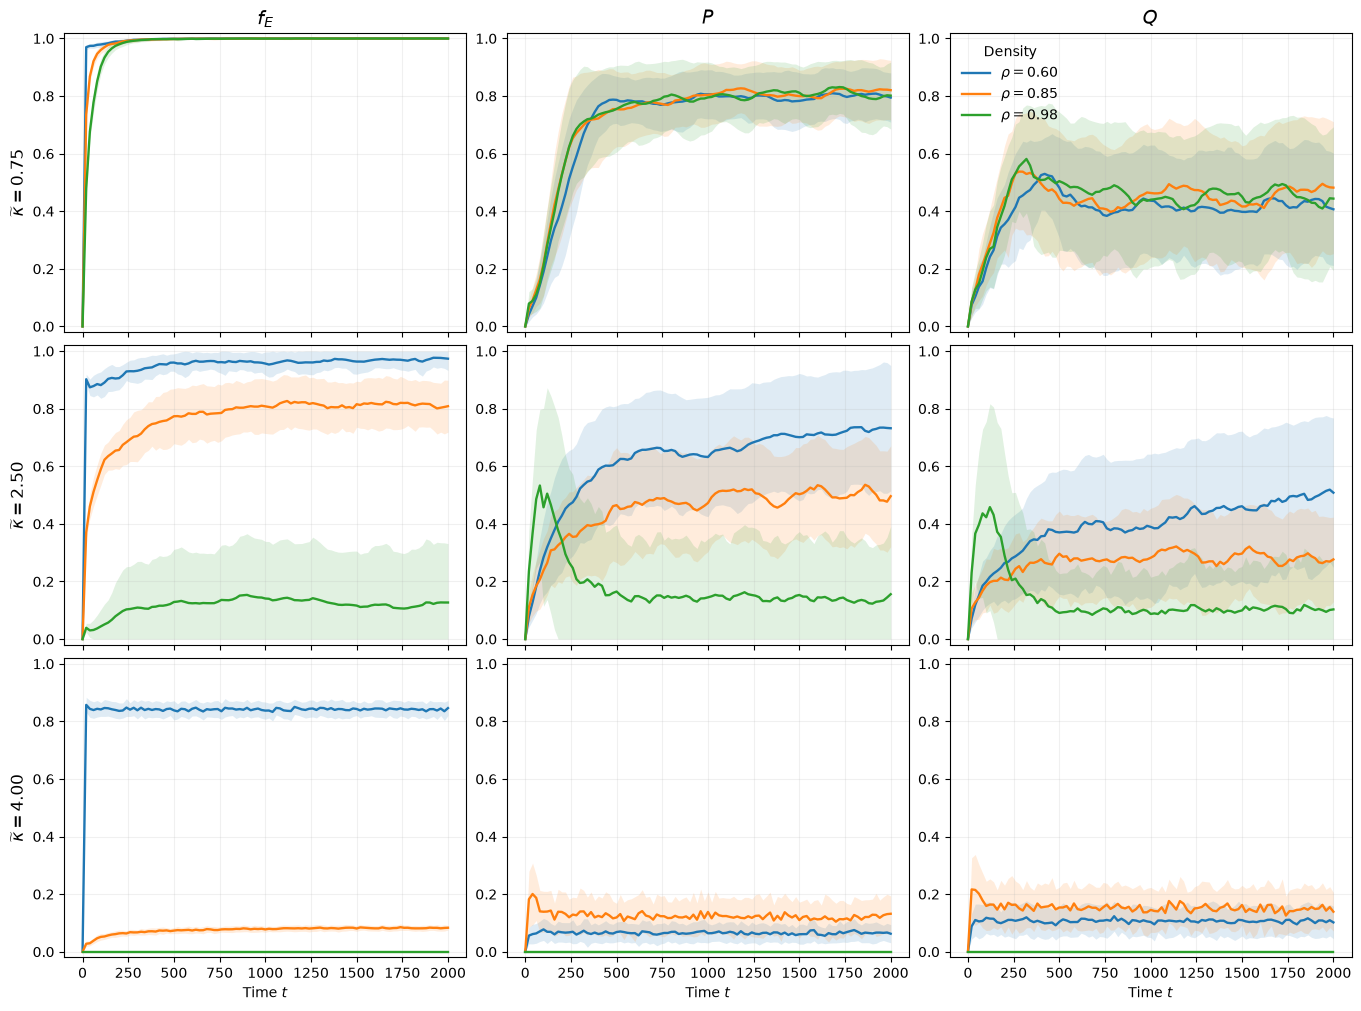

In [2]:
rhos = (0.60, 0.85, 0.98)
kappas = (0.75, 2.50, 4.00)

fig, axes = plt.subplots(
    len(kappas), len(observables),
    figsize=(13.5, 10.0), sharex=True, sharey="col",
    constrained_layout=True,
)

for row, kappa in enumerate(kappas):
    for col, (name, label) in enumerate(observables.items()):
        ax = axes[row, col]
        for rho in rhos:
            series = ensemble.loc[
                np.isclose(ensemble["rho"], rho)
                & np.isclose(ensemble["kappa"], kappa)
            ].sort_values("time")
            if series.empty:
                raise ValueError(f"Missing data for rho={rho}, kappa={kappa}")

            t = series["time"].to_numpy()
            mean = series[f"{name}_mean"].to_numpy()
            sd = series[f"{name}_std"].fillna(0).to_numpy()
            line, = ax.plot(t, mean, lw=1.7, label=rf"$\rho={rho:.2f}$")
            ax.fill_between(
                t, np.clip(mean - sd, 0, 1), np.clip(mean + sd, 0, 1),
                color=line.get_color(), alpha=0.14, linewidth=0,
            )

        if row == 0:
            ax.set_title(label, fontsize=14)
        if col == 0:
            ax.set_ylabel(rf"$\widetilde{{\kappa}}={kappa:.2f}$", fontsize=12)
        if row == len(kappas) - 1:
            ax.set_xlabel(r"Time $t$")
        ax.set_ylim(-0.02, 1.02)
        ax.grid(alpha=0.18)

axes[0, -1].legend(title="Density", loc="best", frameon=False)
figure_dir = root / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_dir / "temporal_morphology_and_order.png", dpi=200, bbox_inches="tight")
plt.show()

## Dynamical observables

Morphology and orientational order appear to settle in the representative cases, but this does **not** establish dynamical stationarity. We also examine the mean instantaneous mechanical speed, the polarization of cell velocities, and the mean-squared displacement (MSD) from the initial configuration.

- **Mean speed** measures instantaneous mechanical activity (self-propulsion plus interaction-induced motion).
- **Velocity polarization** measures coherence of velocity directions. It is undefined when the total speed vanishes, rather than being assigned zero.
- **MSD from $t=0$** uses *unwrapped* positions under periodic boundary conditions, with a single time origin. Its continued growth is compatible with stationary motion; a plateau is **not** expected in a moving state. A strongly polarized, drifting system may exhibit approximately ballistic growth.

We use the same nine representative conditions as above. This is an exploratory comparison, not a formal stationarity test.

In [3]:
motion_path = root / "processed" / "motion" / "motion.parquet"
motion_columns = [
    "rho", "kappa", "seed", "time",
    "mean_instantaneous_speed", "velocity_polarization", "msd_t0",
]
motion = pd.read_parquet(motion_path, columns=motion_columns)

motion_observables = {
    "mean_instantaneous_speed": r"Mean speed $\langle |\mathbf{v}|\rangle$",
    "velocity_polarization": r"Velocity polarization $P_v$",
    "msd_t0": r"MSD from $t=0$",
}

motion_aggregations = {
    f"{name}_{stat}": (name, stat)
    for name in motion_observables
    for stat in ("mean", "std")
}
motion_ensemble = (
    motion.groupby(["rho", "kappa", "time"], as_index=False)
    .agg(**motion_aggregations)
    .sort_values(["rho", "kappa", "time"])
)

print(f"Loaded {len(motion):,} motion snapshots.")

Loaded 129,280 motion snapshots.


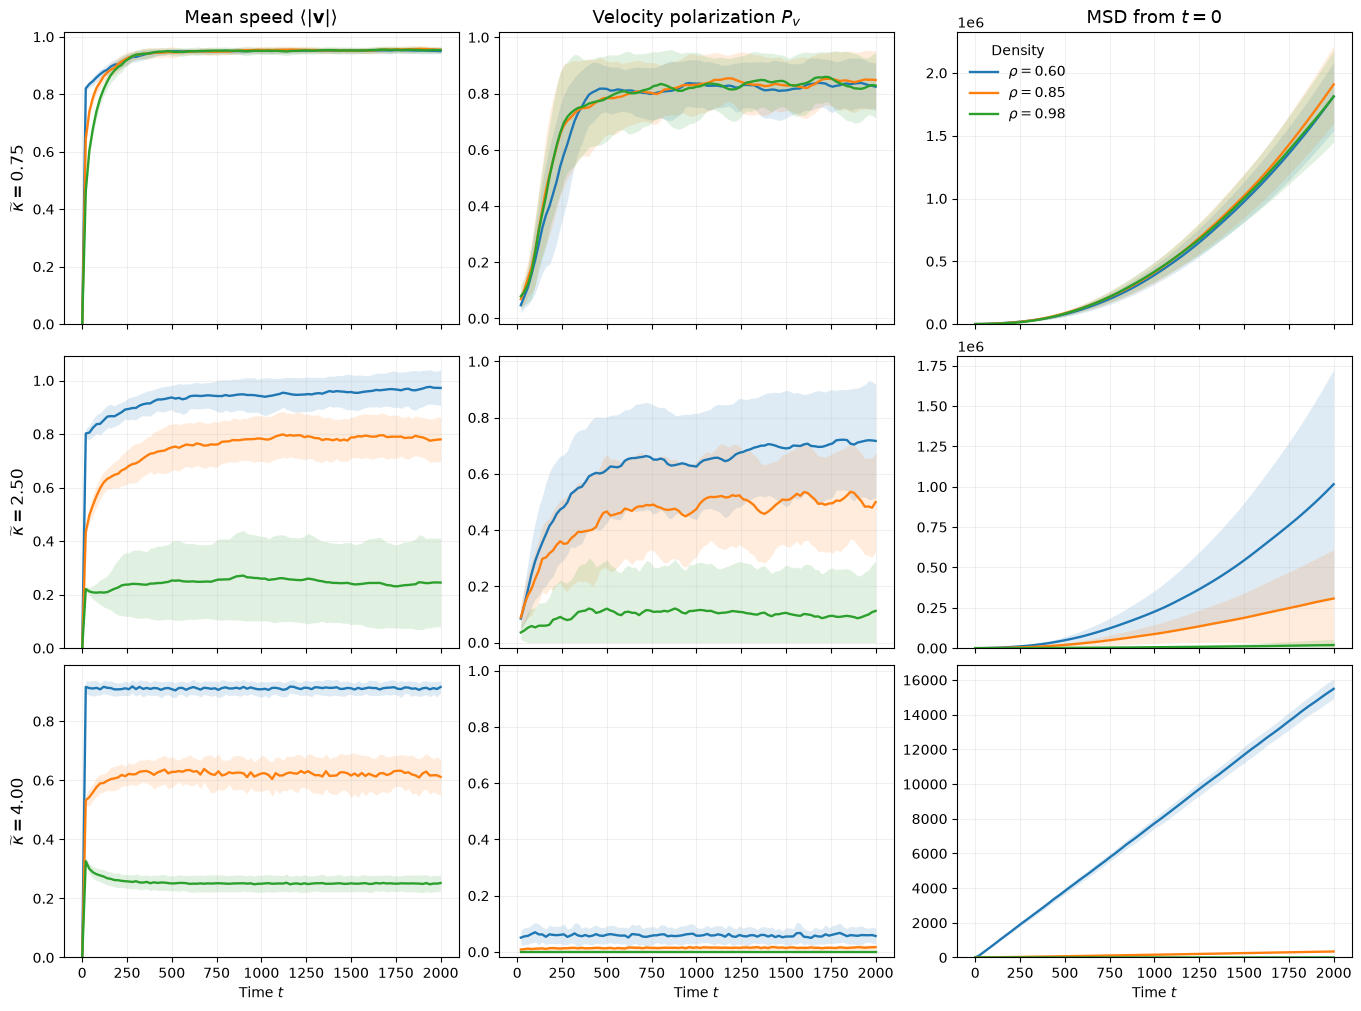

In [4]:
fig, axes = plt.subplots(
    len(kappas), len(motion_observables),
    figsize=(13.5, 10.0), sharex=True,
    constrained_layout=True,
)

for row, kappa in enumerate(kappas):
    for col, (name, title) in enumerate(motion_observables.items()):
        ax = axes[row, col]
        for rho in rhos:
            series = motion_ensemble.loc[
                np.isclose(motion_ensemble["rho"], rho)
                & np.isclose(motion_ensemble["kappa"], kappa)
            ].sort_values("time")
            if series.empty:
                raise ValueError(f"Missing motion data for rho={rho}, kappa={kappa}")

            t = series["time"].to_numpy()
            mean = series[f"{name}_mean"].to_numpy()
            sd = series[f"{name}_std"].to_numpy()
            line, = ax.plot(t, mean, lw=1.7, label=rf"$\rho={rho:.2f}$")

            lower = np.maximum(mean - sd, 0.0)
            upper = mean + sd
            if name == "velocity_polarization":
                upper = np.minimum(upper, 1.0)
            ax.fill_between(
                t, lower, upper,
                color=line.get_color(), alpha=0.14, linewidth=0,
            )

        if row == 0:
            ax.set_title(title, fontsize=13)
        if col == 0:
            ax.set_ylabel(rf"$\widetilde{{\kappa}}={kappa:.2f}$", fontsize=12)
        if row == len(kappas) - 1:
            ax.set_xlabel(r"Time $t$")
        if name == "velocity_polarization":
            ax.set_ylim(-0.02, 1.02)
        else:
            ax.set_ylim(bottom=0)
        ax.grid(alpha=0.18)

axes[0, -1].legend(title="Density", loc="best", frameon=False)
figure_dir = root / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_dir / "temporal_motion.png", dpi=200, bbox_inches="tight")
plt.show()

## Interpretation

The representative time series allow us to judge whether the **means of instantaneous observables** (morphology, order, speed and velocity polarization) develop clear late-time trends. An approximately constant mean is evidence of relaxation in these observables, but does not by itself prove full statistical stationarity or characterize all 20 parameter points.

In contrast, the MSD is a *cumulative* quantity from a single origin ($t=0$): its continued growth is compatible with stationary motion, and its scaling should not be interpreted as an instantaneous order parameter. Low velocity polarization with nonzero mean speed also need not imply zero mobility.

At $\widetilde\kappa=2.50$ and $\rho=0.60$, the ensemble-averaged polar/nematic order and velocity polarization still exhibit a mild upward trend near $T=2000$. This case should not be treated as demonstrably stationary without checking the sensitivity to the late-time averaging window.

The state-diagram analysis will use late-time data to compare all 20 parameter combinations. We leave detailed cluster statistics for spatial/state-diagram analysis and defer interpreting local order until the coarse-graining length dependence is assessed.